# 01 · Dataset Understanding & Profiling (Phase 1)

**Goal:** understand the raw IPL data *before* any cleaning.
This notebook reads only `data/raw/` and never writes to it. Every check here is
implemented in `python/01_data_profiling.py` (the reproducible source of truth);
the notebook calls those same functions so the numbers match the saved reports.

In [1]:
import sys
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / 'python'))
import ipl_config as cfg
import importlib; prof = importlib.import_module('01_data_profiling')

pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
FIG_DIR = cfg.PROFILING_DIR / 'figures'; FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Confirm access and integrity of the raw files

In [2]:
files = prof.verify_raw_files()
pd.DataFrame(files).T

,path,bytes,sha256
matches.csv,data\raw\matches.csv,225266,8a0394246d2a76b44526565f2245d8f4feff91babe57ab...
deliveries.csv,data\raw\deliveries.csv,27019953,142236ea52950795dab266d4aa392c7645bd1a0db4704f...


## 2. Load and inspect dimensions

In [3]:
matches, deliveries = prof.load_raw()
matches_txt, deliveries_txt = prof.load_raw_as_text()
print('matches   :', matches.shape)
print('deliveries:', deliveries.shape)

matches   : (1095, 20)
deliveries: (260920, 17)


In [4]:
matches.head()

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


In [5]:
deliveries.head(8)

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
5,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,6,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
6,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,7,BB McCullum,P Kumar,SC Ganguly,0,1,1,legbyes,0,NaN,NaN,NaN
7,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,1,1,BB McCullum,Z Khan,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


## 3. Data types

In [6]:
pd.concat({'matches': matches.dtypes, 'deliveries': deliveries.dtypes}, axis=1)

,matches,deliveries
id,int64,NaN
season,object,NaN
city,object,NaN
date,object,NaN
match_type,object,NaN
player_of_match,object,NaN
venue,object,NaN
team1,object,NaN
team2,object,NaN
toss_winner,object,NaN


## 4. Column profiles (missing values, encoding, cardinality)
Missing values are encoded as the literal text `NA` in most columns, but as an **empty string** in
`deliveries.extras_type`. Pandas treats both as missing by default; the profile shows both encodings.

In [7]:
prof.column_profile(matches, matches_txt).drop(columns='top_values')

,column,row_count,pandas_dtype,non_null,missing,missing_pct,encoded_as_literal_NA,encoded_as_blank,unique_values,min,max
0,id,1095,int64,1095,0,0.000,0,0,1095,335982.0,1426312.0
1,season,1095,object,1095,0,0.000,0,0,17,NaN,NaN
2,city,1095,object,1044,51,4.658,51,0,36,NaN,NaN
3,date,1095,object,1095,0,0.000,0,0,823,NaN,NaN
4,match_type,1095,object,1095,0,0.000,0,0,8,NaN,NaN
5,player_of_match,1095,object,1090,5,0.457,5,0,291,NaN,NaN
6,venue,1095,object,1095,0,0.000,0,0,58,NaN,NaN
7,team1,1095,object,1095,0,0.000,0,0,19,NaN,NaN
8,team2,1095,object,1095,0,0.000,0,0,19,NaN,NaN
9,toss_winner,1095,object,1095,0,0.000,0,0,19,NaN,NaN


In [8]:
prof.column_profile(deliveries, deliveries_txt).drop(columns='top_values')

,column,row_count,pandas_dtype,non_null,missing,missing_pct,encoded_as_literal_NA,encoded_as_blank,unique_values,min,max
0,match_id,260920,int64,260920,0,0.000,0,0,1095,335982.0,1426312.0
1,inning,260920,int64,260920,0,0.000,0,0,6,1.0,6.0
2,batting_team,260920,object,260920,0,0.000,0,0,19,NaN,NaN
3,bowling_team,260920,object,260920,0,0.000,0,0,19,NaN,NaN
4,over,260920,int64,260920,0,0.000,0,0,20,0.0,19.0
5,ball,260920,int64,260920,0,0.000,0,0,11,1.0,11.0
6,batter,260920,object,260920,0,0.000,0,0,673,NaN,NaN
7,bowler,260920,object,260920,0,0.000,0,0,530,NaN,NaN
8,non_striker,260920,object,260920,0,0.000,0,0,663,NaN,NaN
9,batsman_runs,260920,int64,260920,0,0.000,0,0,7,0.0,6.0


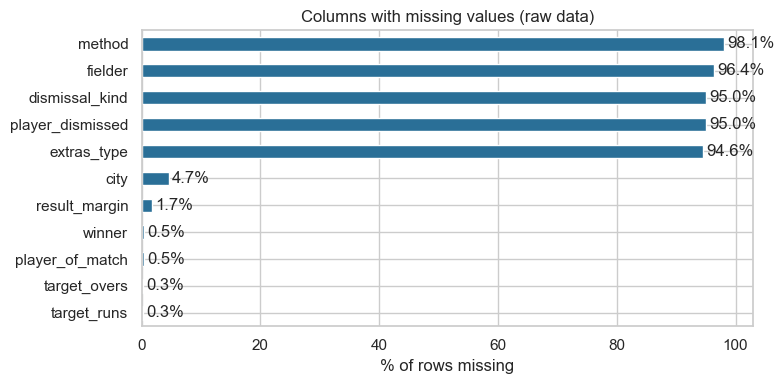

In [9]:
miss = pd.concat([matches.isna().mean().rename('matches'), deliveries.isna().mean().rename('deliveries')]).mul(100)
miss = miss[miss > 0].sort_values()
ax = miss.plot.barh(figsize=(8, 4), color='#2a6f97')
ax.set_xlabel('% of rows missing'); ax.set_title('Columns with missing values (raw data)')
for i, v in enumerate(miss): ax.text(v + 0.5, i, f'{v:.1f}%', va='center')
plt.tight_layout(); plt.savefig(FIG_DIR / 'missing_values.png', dpi=150); plt.show()

Most missing values are **structural**, not errors: `player_dismissed`, `dismissal_kind` and `fielder`
exist only on wicket balls; `extras_type` only on extras; `method` only on rain-affected (D/L) matches.

## 5. Coverage: seasons, matches, teams, venues

In [10]:
cov = prof.season_coverage(matches, deliveries)
cov

,season,calendar_year,matches,first_match,last_match,teams,venues,deliveries,no_result,ties_super_over,dls_matches
0,2007/08,2008,58,2008-04-18,2008-06-01,8,9,13489,0,0,2
1,2009,2009,57,2009-04-18,2009-05-24,8,8,13606,0,1,3
2,2009/10,2010,60,2010-03-12,2010-04-25,8,13,14498,0,1,0
3,2011,2011,73,2011-04-08,2011-05-28,10,12,17013,1,0,3
4,2012,2012,74,2012-04-04,2012-05-27,9,12,17767,0,0,0
5,2013,2013,76,2013-04-03,2013-05-26,9,13,18177,0,2,0
6,2014,2014,60,2014-04-16,2014-06-01,8,13,14300,0,1,1
7,2015,2015,59,2015-04-08,2015-05-24,8,13,13652,2,1,2
8,2016,2016,60,2016-04-09,2016-05-29,8,11,14096,0,0,4
9,2017,2017,59,2017-04-05,2017-05-21,8,11,13862,0,1,1


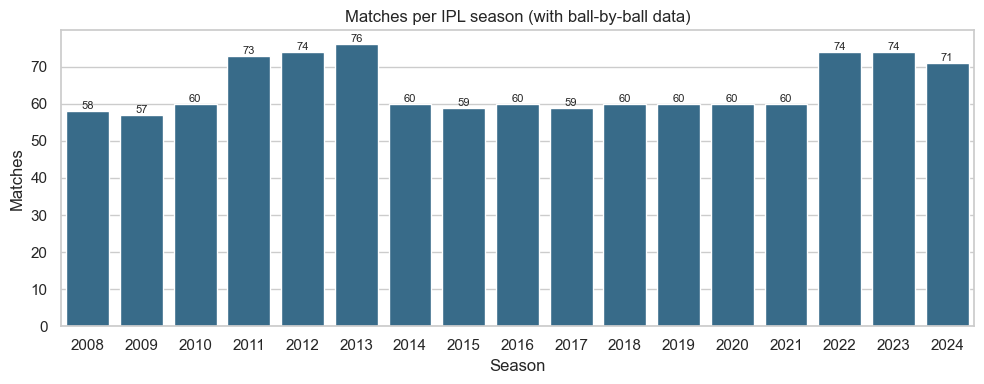

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=cov, x='calendar_year', y='matches', color='#2a6f97', ax=ax)
ax.set_title('Matches per IPL season (with ball-by-ball data)'); ax.set_xlabel('Season'); ax.set_ylabel('Matches')
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / 'matches_per_season.png', dpi=150); plt.show()

In [12]:
prof.team_eras(matches)

,team,first_year,last_year,matches
0,Chennai Super Kings,2008,2024,238
1,Deccan Chargers,2008,2012,75
2,Delhi Daredevils,2008,2018,161
3,Kings XI Punjab,2008,2020,190
4,Kolkata Knight Riders,2008,2024,251
5,Mumbai Indians,2008,2024,261
6,Rajasthan Royals,2008,2024,221
7,Royal Challengers Bangalore,2008,2023,240
8,Kochi Tuskers Kerala,2011,2011,14
9,Pune Warriors,2011,2013,46


In [13]:
v = prof.venue_variants(matches)
v[v.variants_for_base > 1]

,base,venue,matches,cities,variants_for_base
23,m chinnaswamy stadium,M Chinnaswamy Stadium,65,Bangalore,3
24,m chinnaswamy stadium,"M Chinnaswamy Stadium, Bengaluru",14,Bengaluru,3
25,m chinnaswamy stadium,M.Chinnaswamy Stadium,15,Bengaluru,3
26,ma chidambaram stadium,MA Chidambaram Stadium,9,Chennai,3
27,ma chidambaram stadium,"MA Chidambaram Stadium, Chepauk",48,Chennai,3
28,ma chidambaram stadium,"MA Chidambaram Stadium, Chepauk, Chennai",28,Chennai,3
37,punjab cricket association is bindra stadium,Punjab Cricket Association IS Bindra Stadium,10,Chandigarh,3
38,punjab cricket association is bindra stadium,"Punjab Cricket Association IS Bindra Stadium, ...",11,Chandigarh,3
39,punjab cricket association is bindra stadium,"Punjab Cricket Association IS Bindra Stadium, ...",5,Chandigarh,3
41,rajiv gandhi international stadium,Rajiv Gandhi International Stadium,15,Hyderabad,3


## 6. Relationship and data-quality checks

In [14]:
checks, ev = prof.run_checks(matches, deliveries)
print(checks.status.value_counts().to_string())
checks

status
PASS    37
INFO    10
FLAG     8


,check_id,area,check,observed,status,note
0,S01,Keys,matches.id is unique,1095 unique of 1095,PASS,
1,S02,Duplicates,Fully duplicated rows in matches,0,PASS,
2,S03,Duplicates,Fully duplicated rows in deliveries,0,PASS,
3,S04,Keys,"(match_id, inning, over, ball) is unique in de...",0,PASS,Natural composite key for a delivery
4,S05,Duplicates,Same date + same teams appearing twice in matches,0,PASS,
5,R01,Relationship,Deliveries whose match_id is not in matches (o...,0,PASS,
6,R02,Relationship,Matches with no deliveries,0,PASS,
7,R03,Relationship,Delivery batting/bowling teams not matching ma...,0,PASS,
8,R04,Relationship,Deliveries where batting_team == bowling_team,0,PASS,
9,R05,Relationship,player_of_match names not found in deliveries,0,PASS,


In [15]:
checks[checks.status == 'FLAG']

,check_id,area,check,observed,status,note
17,M08,Match,Missing city,51 rows; venues={'Dubai International Cricket ...,FLAG,Recoverable from venue name (UAE venues)
20,M11,Format,Season labels that differ from the calendar ye...,"'2007/08'->2008, '2009/10'->2010, '2020/21'->2020",FLAG,Season must be derived from date in Phase 2
27,C07,Semantics,team1 column always = team batting first?,only 72.6% of matches,FLAG,team1/team2 are NOT batting order; derive batt...
39,D12,Wickets,'retired hurt' flagged as is_wicket = 1,15,FLAG,Retired hurt is NOT a dismissal (batter is not...
46,O05,Overs,Overs with more than 6 legal deliveries,29,FLAG,Source shows 7 legal balls; likely umpire misc...
49,N01,Names,Distinct team-name strings,19,FLAG,Includes renamed franchises and spelling varia...
50,N02,Names,Distinct venue strings,58,FLAG,Same ground appears under several names - see ...
51,N03,Names,City spelling variants (Bangalore/Bengaluru),"['Bangalore', 'Bengaluru']",FLAG,


## 7. Cricket-specific structure

In [16]:
pd.crosstab(deliveries.extras_type.fillna('(none)'), deliveries.extra_runs, margins=True)

extra_runs,0,1,2,3,4,5,7,All
extras_type,,,,,,,,
(none),246795,0,0,0,0,0,0,246795
byes,0,447,43,3,172,8,0,673
legbyes,0,3450,198,22,325,6,0,4001
noballs,0,1053,9,1,0,6,0,1069
penalty,0,0,0,0,0,1,1,2
wides,0,7678,335,56,7,304,0,8380
All,246795,12628,585,82,504,325,1,260920


In [17]:
pd.crosstab(deliveries.dismissal_kind, deliveries.is_wicket)

is_wicket,1
dismissal_kind,
bowled,2212
caught,8063
caught and bowled,367
hit wicket,15
lbw,800
obstructing the field,3
retired hurt,15
retired out,3
run out,1114


In [18]:
print('Legal deliveries per over:', ev['legal_balls_per_over'])
ev['seven_ball_overs']

Legal deliveries per over: {0: 4, 1: 117, 2: 108, 3: 109, 4: 150, 5: 150, 6: 41543, 7: 29}


,match_id,inning,over
0,335994,2,10
1,392198,2,10
2,419155,1,18
3,729309,2,4
4,1136564,2,11
5,1178407,1,16
6,1216497,2,4
7,1216500,1,18
8,1216500,2,14
9,1216510,1,9


## 8. Summary
See `reports/profiling/dataset_profiling_report.md`, `reports/validation/phase1_initial_data_quality_report.md`
and `documentation/` for the written data dictionary, relationship notes and Phase 2 decisions.